#  House Price Prediction
**Algorithm**
  - Multiple Linear Regression & Random Forest Regression

**Method**
- 80:20 train–test split (random_state=42)
- Binary encoding for yes/no features and one-hot encoding for furnishingstatus
- StandardScaler for Multiple Linear Regression; Random Forest uses unscaled features
- Multiple Linear Regression: default parameters
- Random Forest: n_estimators=200; GridSearchCV for hyperparameter tuning (5-fold CV)
- Evaluation: MAE, RMSE, R² score, 5-fold cross-validation, and prediction comparison plots

**Dataset:**
[Housing Prices Dataset (yasserh)](https://www.kaggle.com/datasets/yasserh/housing-prices-dataset)


## 1. Import libraries & load data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_style('whitegrid')
df = pd.read_csv('/kaggle/input/datasets/mafruda/dataset/House price dataset.csv')
df.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


## 2. Exploratory Data Analysis (EDA)

In [2]:
print('Shape:', df.shape)
print('\nMissing values:\n', df.isnull().sum())
print('\nDuplicates:', df.duplicated().sum())
df.info()

Shape: (545, 13)

Missing values:
 price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64

Duplicates: 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    object
 6   guestroom         545 non-null    object
 7   basement          545 non-null    object
 8   hotwaterheating   545 non-null    object
 9   airconditioning   545 non-null    o

In [3]:
df.describe()

,price,area,bedrooms,bathrooms,stories,parking
count,5.450000e+02,545.000000,545.000000,545.000000,545.000000,545.000000
mean,4.766729e+06,5150.541284,2.965138,1.286239,1.805505,0.693578
std,1.870440e+06,2170.141023,0.738064,0.502470,0.867492,0.861586
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,3.430000e+06,3600.000000,2.000000,1.000000,1.000000,0.000000
50%,4.340000e+06,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,5.740000e+06,6360.000000,3.000000,2.000000,2.000000,1.000000
max,1.330000e+07,16200.000000,6.000000,4.000000,4.000000,3.000000


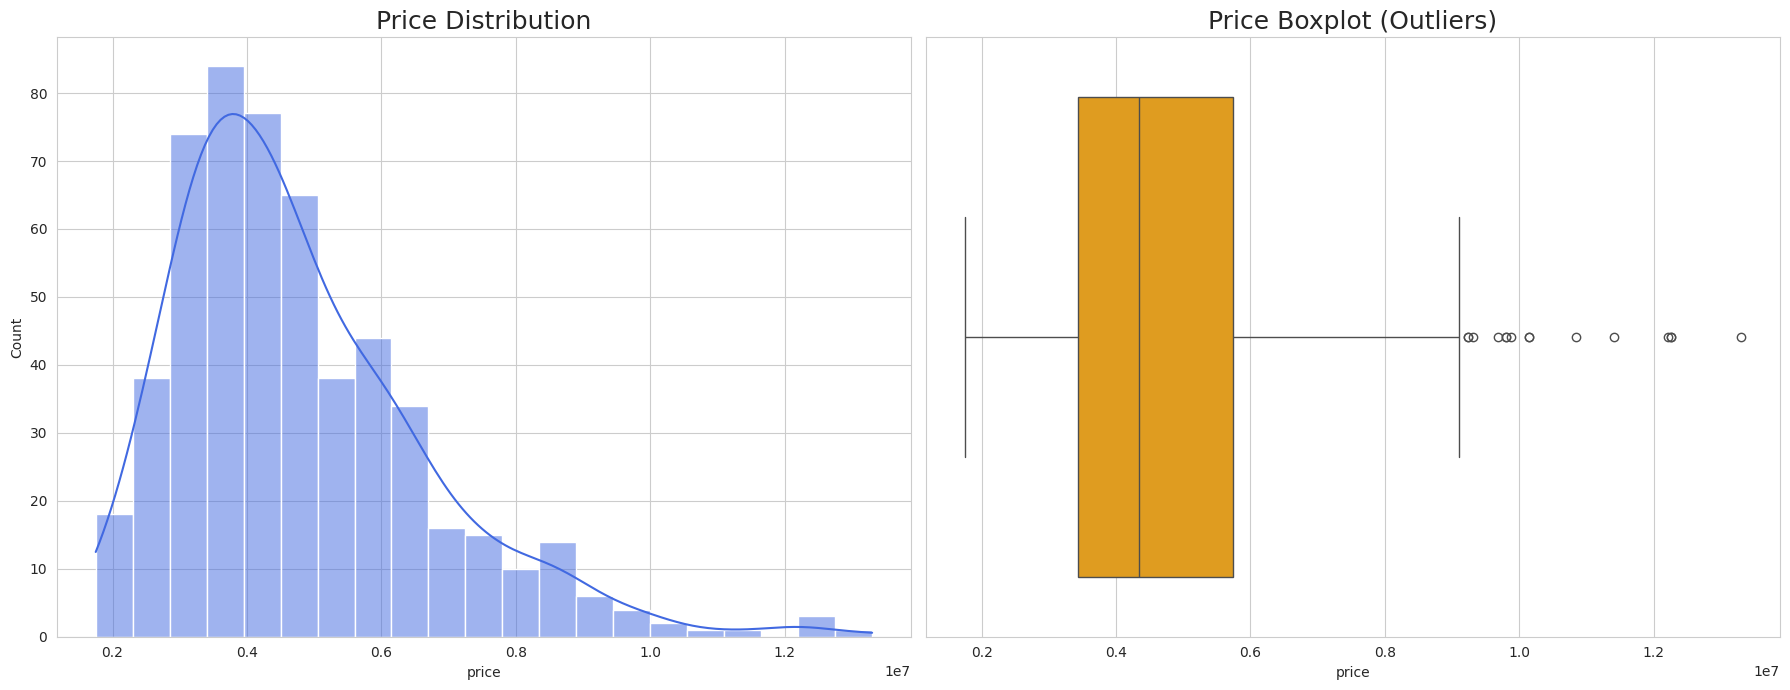

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(18, 7))

sns.histplot(df['price'], kde=True, ax=ax[0], color='royalblue')
ax[0].set_title('Price Distribution', fontsize=18)

sns.boxplot(x=df['price'], ax=ax[1], color='orange')
ax[1].set_title('Price Boxplot (Outliers)', fontsize=18)

plt.tight_layout()
plt.show()

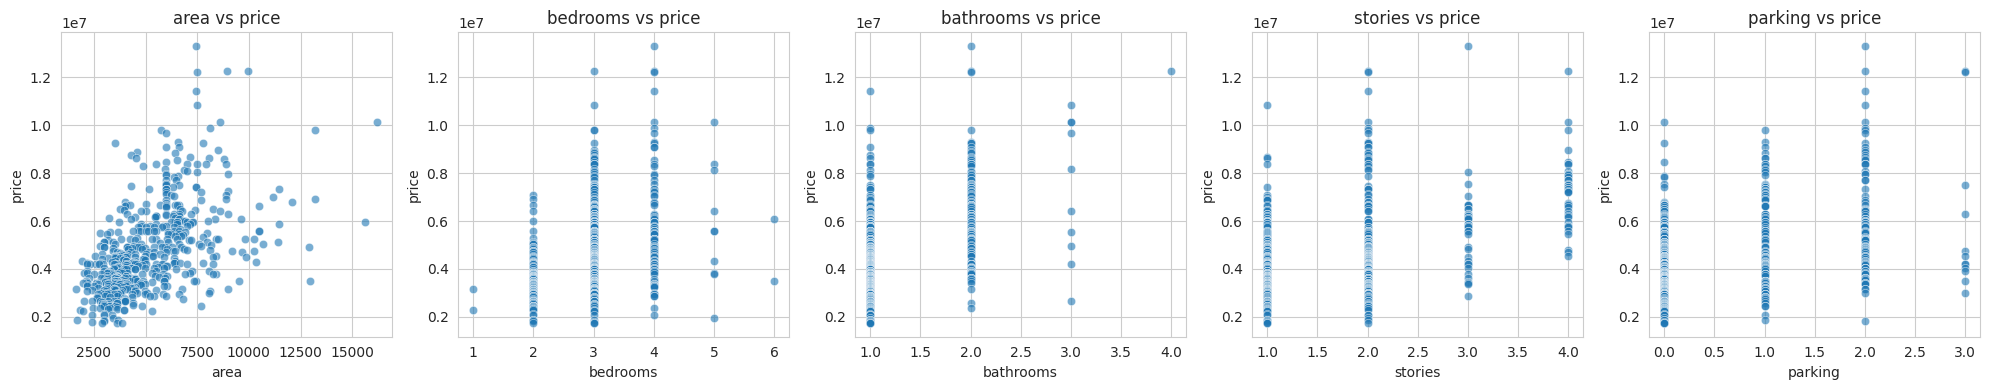

In [5]:
num_cols = ['area', 'bedrooms', 'bathrooms', 'stories', 'parking']
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for a, c in zip(axes, num_cols):
    sns.scatterplot(x=df[c], y=df['price'], ax=a, alpha=0.6)
    a.set_title(f'{c} vs price')
plt.tight_layout(); plt.show()

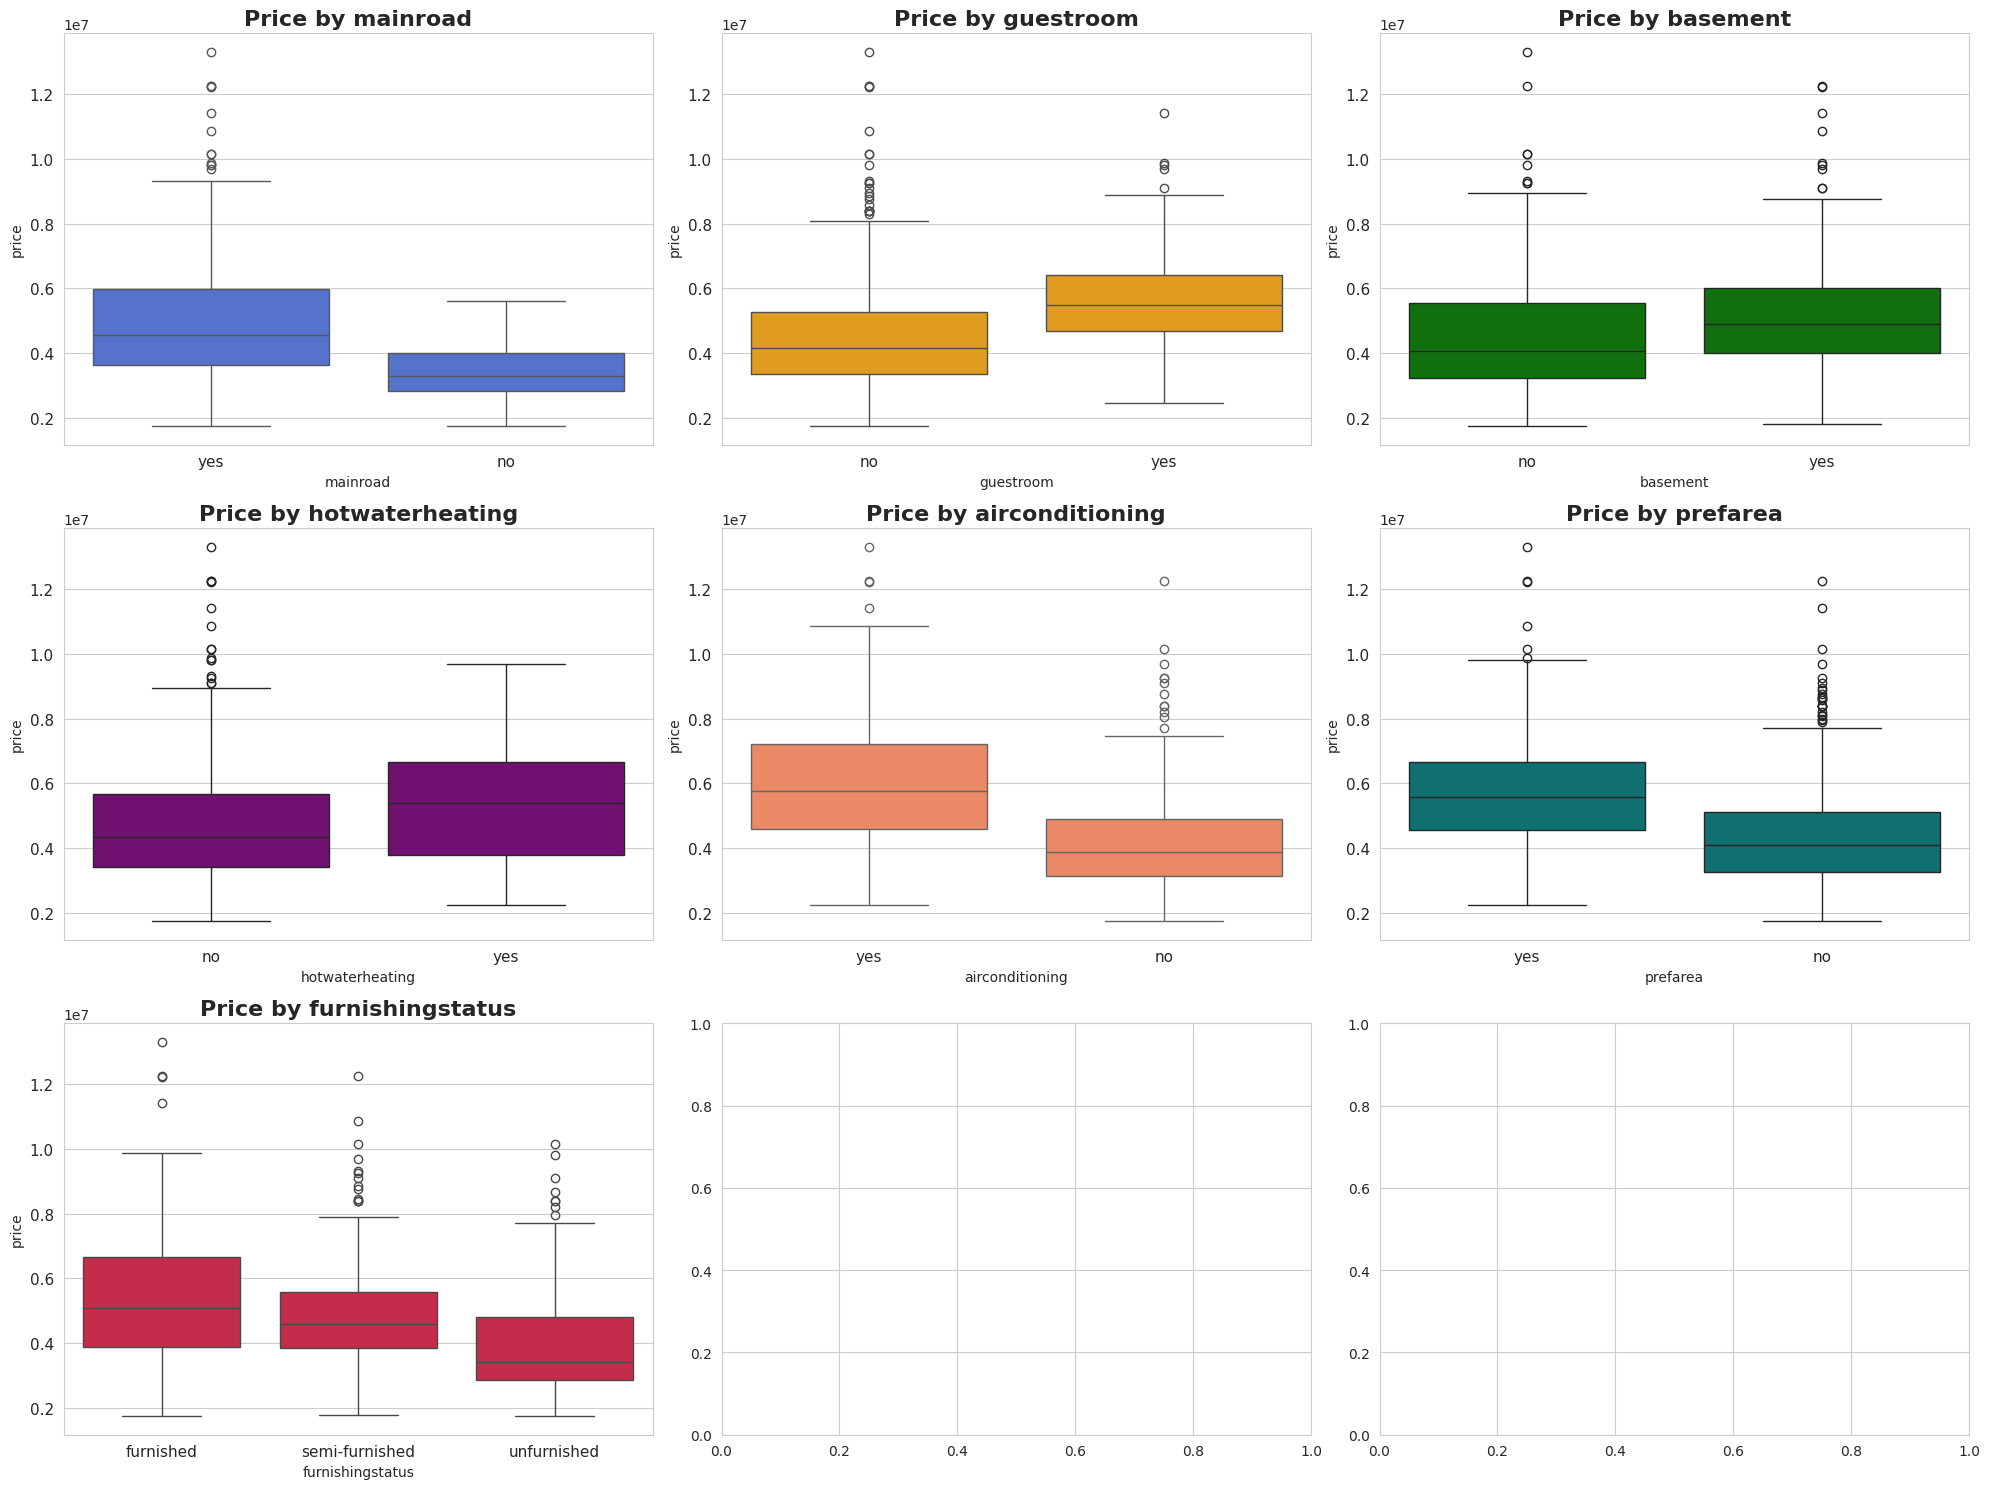

In [6]:
cat_cols = df.select_dtypes(include='object').columns.tolist()

fig, axes = plt.subplots(3, 3, figsize=(20, 15))

colors = ['royalblue', 'orange', 'green', 'purple', 'coral',
          'teal', 'crimson', 'gold', 'deeppink']

for a, c, color in zip(axes.ravel(), cat_cols, colors):
    sns.boxplot(x=df[c], y=df['price'], ax=a, color=color)
    a.set_title(f'Price by {c}', fontsize=16, fontweight='bold')
    a.tick_params(labelsize=11)

plt.tight_layout()
plt.show()

## 3. Preprocessing

- Binary `yes/no` columns → 1/0
- `furnishingstatus` → one-hot encoding
- Outliers: price is right-skewed, but we keep all rows (only 545 samples).

In [7]:
data = df.copy()
bin_cols = ['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea']
for c in bin_cols:
    data[c] = data[c].map({'yes': 1, 'no': 0})

data = pd.get_dummies(data, columns=['furnishingstatus'], drop_first=True, dtype=int)
data.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus_semi-furnished,furnishingstatus_unfurnished
0,13300000,7420,4,2,3,1,0,0,0,1,2,1,0,0
1,12250000,8960,4,4,4,1,0,0,0,1,3,0,0,0
2,12250000,9960,3,2,2,1,0,1,0,0,2,1,1,0
3,12215000,7500,4,2,2,1,0,1,0,1,3,1,0,0
4,11410000,7420,4,1,2,1,1,1,0,1,2,0,0,0


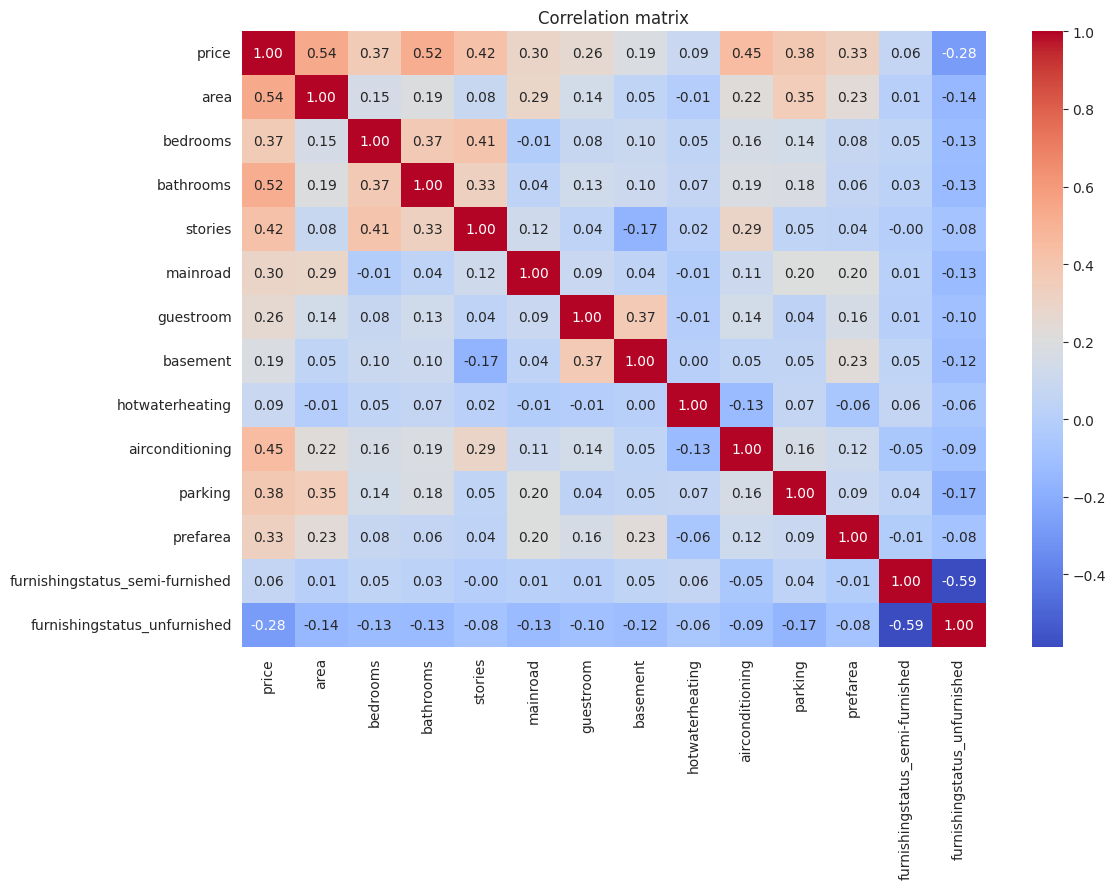

In [8]:
plt.figure(figsize=(12, 8))
sns.heatmap(data.corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation matrix'); plt.show()

In [9]:
X = data.drop('price', axis=1)
y = data['price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Scaling is only needed for linear regression (Random Forest doesn't need it)
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)
print(X_train.shape, X_test.shape)

(436, 13) (109, 13)


## 4. Model 1 — Multiple Linear Regression

In [10]:
lr = LinearRegression()
lr.fit(X_train_sc, y_train)
lr_pred = lr.predict(X_test_sc)

coef = pd.DataFrame({'Feature': X.columns, 'Coefficient': lr.coef_}).sort_values('Coefficient', ascending=False)
coef

,Feature,Coefficient
2,bathrooms,521879.027748
0,area,519552.416340
8,airconditioning,365157.393851
3,stories,349251.438906
10,prefarea,266656.351993
9,parking,192005.953667
6,basement,187067.803214
7,hotwaterheating,149862.702991
4,mainroad,128498.628215
5,guestroom,88768.667686


## 5. Model 2 — Random Forest Regression

In [11]:
rf = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

**Hyperparameter tuning (GridSearchCV)**

In [12]:
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 5, 10, 15],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

grid = GridSearchCV(
    RandomForestRegressor(random_state=42, n_jobs=-1),
    param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1
)

grid.fit(X_train, y_train)

print("Random Forest - Hyperparameter Tuning")
print("\nBest Parameters:")

for key, value in grid.best_params_.items():
    print(f"{key}: {value}")

print(f"\nBest CV R² Score: {grid.best_score_:.4f}")

best_rf = grid.best_estimator_
rf_tuned_pred = best_rf.predict(X_test)

Random Forest - Hyperparameter Tuning

Best Parameters:
max_depth: None
min_samples_leaf: 2
min_samples_split: 10
n_estimators: 100

Best CV R² Score: 0.6172


## 6. Evaluation & comparison

In [13]:
from sklearn.model_selection import KFold
from sklearn.pipeline import make_pipeline

kf = KFold(n_splits=5, shuffle=True, random_state=42)

cv_lr = cross_val_score(make_pipeline(StandardScaler(), LinearRegression()), X, y, cv=kf, scoring='r2')
cv_rf = cross_val_score(best_rf, X, y, cv=kf, scoring='r2')

print(f'Linear Regression CV R2: {cv_lr.mean():.4f} (+/- {cv_lr.std():.4f})')
print(f'Random Forest (tuned) CV R2: {cv_rf.mean():.4f} (+/- {cv_rf.std():.4f})')

Linear Regression CV R2: 0.6324 (+/- 0.0737)
Random Forest (tuned) CV R2: 0.6276 (+/- 0.0424)


In [14]:
def evaluate(name, y_true, y_pred):
    return {
        'Model': name,
        'MAE': mean_absolute_error(y_true, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
        'R2': r2_score(y_true, y_pred),
    }

results = pd.DataFrame([
    evaluate('Multiple Linear Regression', y_test, lr_pred),
    evaluate('Random Forest (default)', y_test, rf_pred),
    evaluate('Random Forest (tuned)', y_test, rf_tuned_pred),
]).set_index('Model')
results.round(4)

,MAE,RMSE,R2
Model,,,
Multiple Linear Regression,9.700434e+05,1.324507e+06,0.6529
Random Forest (default),1.014947e+06,1.399769e+06,0.6124
Random Forest (tuned),1.056576e+06,1.450848e+06,0.5836


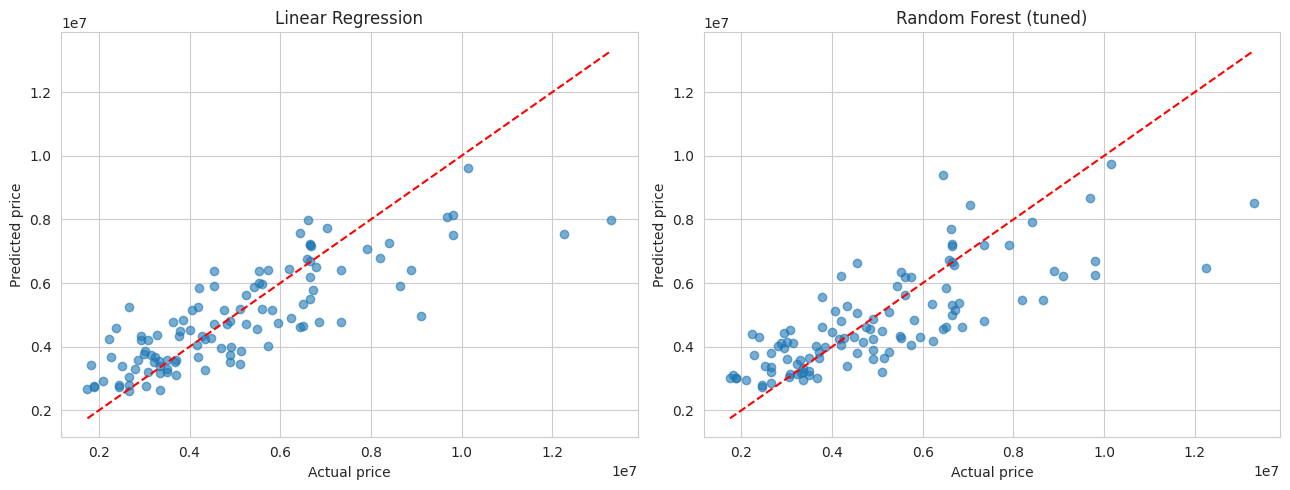

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for a, pred, title in zip(axes, [lr_pred, rf_tuned_pred], ['Linear Regression', 'Random Forest (tuned)']):
    a.scatter(y_test, pred, alpha=0.6)
    lims = [y_test.min(), y_test.max()]
    a.plot(lims, lims, 'r--')
    a.set_xlabel('Actual price'); a.set_ylabel('Predicted price'); a.set_title(title)
plt.tight_layout(); plt.show()

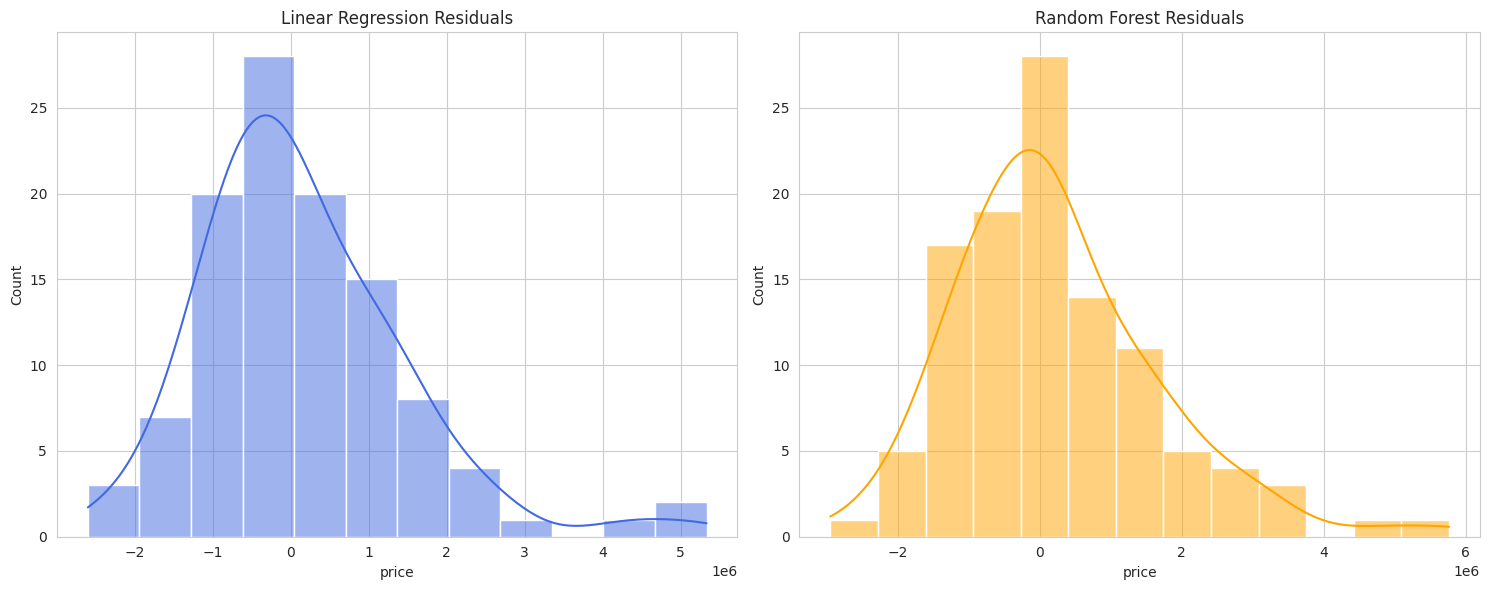

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.histplot(y_test - lr_pred, kde=True, ax=axes[0], color='royalblue')
axes[0].set_title('Linear Regression Residuals')

sns.histplot(y_test - rf_tuned_pred, kde=True, ax=axes[1], color='orange')
axes[1].set_title('Random Forest Residuals')

plt.tight_layout()
plt.show()

## 7. Feature importance (Random Forest)

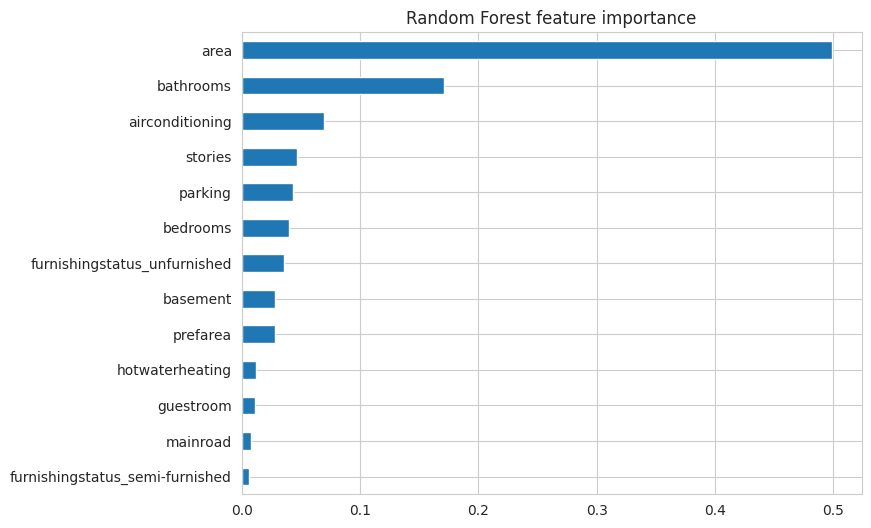

In [17]:
imp = pd.Series(best_rf.feature_importances_, index=X.columns).sort_values()
imp.plot(kind='barh', figsize=(8, 6), title='Random Forest feature importance')
plt.show()

## 8. Predict a new house

In [18]:
sample = pd.DataFrame([{
    'area': 6000, 'bedrooms': 3, 'bathrooms': 2, 'stories': 2, 'mainroad': 1, 'guestroom': 0,
    'basement': 1, 'hotwaterheating': 0, 'airconditioning': 1, 'parking': 2, 'prefarea': 1,
    'furnishingstatus_semi-furnished': 1, 'furnishingstatus_unfurnished': 0,
}])[X.columns]
print('RF predicted price :', round(best_rf.predict(sample)[0]))
print('LR predicted price :', round(lr.fit(X_train_sc, y_train).predict(scaler.fit(X_train).transform(sample))[0]))

RF predicted price : 8366886
LR predicted price : 7412314


**Conclusion**
- Multiple Linear Regression achieved the best test performance (R² = 0.65).
- Both models showed similar 5-fold cross-validation results (R² ≈ 0.63).
- Linear Regression performed better on this small dataset.
- Area, bathrooms, air conditioning, and stories were key price-related features.